# 01 - Weather behaviour, hazard indicators, cyclone exposure and validation
**Climate Sentinel Kenya** - 14 counties (arid north-east, Lake Victoria basin, central highlands, coast).

Run `python run_all.py` first; this notebook only reads `outputs/` so every number here is reproducible.

> **Rainfall is a model estimate, not a rain-gauge reading.** It comes from the ERA5 reanalysis (via Open-Meteo):
> a weather model constrained by observations on a ~25 km grid. It is smooth in space, can miss local convective
> storms, tends to put too many light-rain days in the tropics and can under-estimate extreme daily totals.
> Thresholds are therefore *relative to each location's own ERA5 history*, never absolute mm values from gauges.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sentinel import config as C
OUT, RAW = C.OUT_DIR, C.RAW_DIR
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
csv = lambda n, **k: pd.read_csv(OUT / n, **k)
summary = json.loads((OUT / "run_summary.json").read_text())
print("Daily data:", summary["daily_range"], "| built", summary["built_utc"])

Daily data: ['1991-01-01', '2026-11-05'] | built 2026-11-13T06:35:47+00:00


## 0. Data provenance and coverage

In [2]:
acc = RAW / "ACCESS_LOG.json"
print(json.dumps(json.loads(acc.read_text()), indent=1) if acc.exists() else "no access log (offline build)")
daily = pd.read_parquet(RAW / "daily_all.parquet")
cov = daily.groupby("county").agg(first=("date", "min"), last=("date", "max"), days=("date", "size"),
                                  missing_rain=("precip", lambda s: int(s.isna().sum())),
                                  grid_lat=("grid_lat", "first"), grid_lon=("grid_lon", "first"))
pts = pd.DataFrame([(c.name, c.town, c.lat, c.lon) for c in C.COUNTIES], columns=["county", "town", "lat", "lon"]).set_index("county")
cov = cov.join(pts)
cov["grid_offset_km"] = (111 * np.hypot(cov.grid_lat - cov.lat, (cov.grid_lon - cov.lon) * np.cos(np.radians(cov.lat)))).round(1)
cov

{
 "geoboundaries_KEN_ADM1": {
  "url": "https://github.com/wmgeolab/geoBoundaries/raw/9469f09/releaseData/gbOpen/KEN/ADM1/geoBoundaries-KEN-ADM1_simplified.geojson",
  "accessed_utc": "2026-11-12T10:55:32+00:00"
 },
 "worldpop_2020_1km_unadj": {
  "url": "https://data.worldpop.org/GIS/Population/Global_2000_2020_1km_UNadj/2020/KEN/ken_ppp_2020_1km_Aggregated_UNadj.tif",
  "accessed_utc": "2026-11-12T10:55:42+00:00"
 },
 "noaa_cpc_oni": {
  "url": "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt",
  "accessed_utc": "2026-11-12T10:55:46+00:00"
 },
 "noaa_psl_dmi": {
  "url": "https://psl.noaa.gov/gcos_wgsp/Timeseries/Data/dmi.had.long.data",
  "accessed_utc": "2026-11-12T10:55:46+00:00"
 },
 "ibtracs_SI": {
  "url": "https://www.ncei.noaa.gov/data/international-best-track-archive-for-climate-stewardship-ibtracs/v04r01/access/csv/ibtracs.SI.list.v04r01.csv",
  "accessed_utc": "2026-11-12T10:58:21+00:00"
 },
 "ibtracs_NI": {
  "url": "https://www.ncei.noaa.gov/data/international-

,first,last,days,missing_rain,grid_lat,grid_lon,town,lat,lon,grid_offset_km
county,,,,,,,,,,
Busia,1991-01-01,2026-11-05,13093,0,0.50,34.00,Busia,0.4608,34.1115,13.1
Garissa,1991-01-01,2026-11-05,13093,0,-0.50,39.75,Garissa,-0.4532,39.6461,12.6
Kilifi,1991-01-01,2026-11-05,13093,0,-3.75,39.75,Kilifi,-3.6305,39.8499,17.3
Kisumu,1991-01-01,2026-11-05,13093,0,0.00,34.75,Kisumu,-0.0917,34.7680,10.4
Kwale,1991-01-01,2026-11-05,13093,0,-4.25,39.50,Kwale,-4.1816,39.4606,8.8
Lamu,1991-01-01,2026-11-05,13093,0,-2.25,40.75,Lamu,-2.2717,40.9020,17.0
Makueni,1991-01-01,2026-11-05,13093,0,-1.75,37.75,Wote,-1.7807,37.6288,13.9
Mandera,1991-01-01,2026-11-05,13093,0,4.00,41.75,Mandera,3.9366,41.8670,14.7
Marsabit,1991-01-01,2026-11-05,13093,0,2.25,38.00,Marsabit,2.3284,37.9899,8.8


## 1. Climatology (1991-2020 normals) and rainy seasons

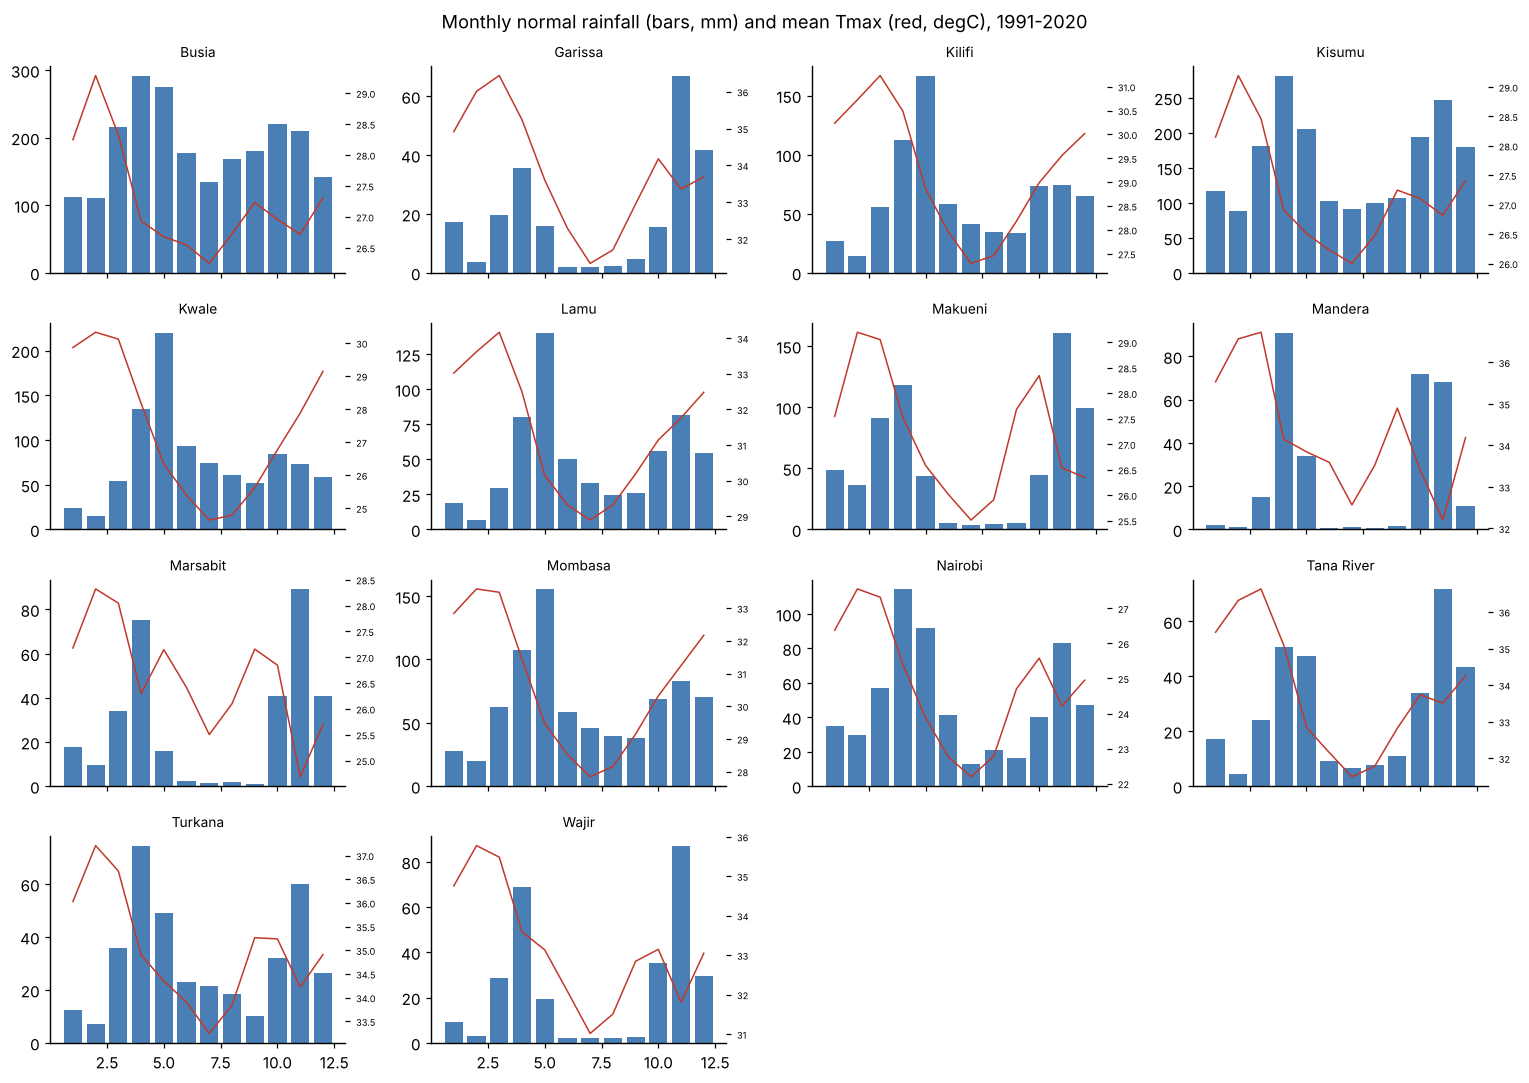

In [3]:
clim = csv("climatology.csv")
fig, axes = plt.subplots(4, 4, figsize=(14, 10), sharex=True)
for ax, (county, g) in zip(axes.flat, clim.groupby("county")):
    ax.bar(g.month, g.precip_mean, color="#4a7fb5"); ax.set_title(county, fontsize=9)
    ax2 = ax.twinx(); ax2.plot(g.month, g.tmax_mean, color="#c0392b", lw=1); ax2.tick_params(labelsize=6)
for ax in axes.flat[len(C.COUNTIES):]: ax.axis("off")
fig.suptitle("Monthly normal rainfall (bars, mm) and mean Tmax (red, degC), 1991-2020"); fig.tight_layout()

In [4]:
seasons = csv("seasons.csv"); seasons

,county,annual_normal_mm,n_rainy_seasons,rainy_seasons,wettest_month,driest_month,regime
0,Busia,2236.5,2,Mar-May (35% of annual); Oct-Nov (19% of annual),Apr,Feb,bimodal
1,Garissa,227.1,2,Mar-Apr (24% of annual); Nov-Dec (48% of annual),Nov,Jul,bimodal
2,Kilifi,756.4,2,Apr-May (37% of annual); Oct-Dec (28% of annual),May,Feb,bimodal
3,Kisumu,1893.8,2,Mar-May (35% of annual); Oct-Dec (33% of annual),Apr,Feb,bimodal
4,Kwale,944.5,2,Apr-Jun (47% of annual); Oct (9% of annual),May,Feb,bimodal
5,Lamu,600.0,2,Apr-May (37% of annual); Oct-Dec (32% of annual),May,Feb,bimodal
6,Makueni,660.6,2,Mar-Apr (32% of annual); Nov-Dec (39% of annual),Nov,Jul,bimodal
7,Mandera,298.6,2,Apr-May (42% of annual); Oct-Nov (47% of annual),Apr,Jun,bimodal
8,Marsabit,329.8,2,Mar-Apr (33% of annual); Oct-Dec (52% of annual),Nov,Sep,bimodal
9,Mombasa,777.8,2,Apr-May (34% of annual); Oct-Dec (28% of annual),May,Feb,bimodal


Wet months are months whose normal is above the county's average month (annual/12); contiguous wet months form a season. Expect **bimodal** regimes (long rains Mar-May, short rains Oct-Dec) in most of Kenya, a later long-rains peak (Apr-Jun) on the coast, and a wetter, flatter regime in the Lake Victoria basin.

## 2. Trends: annual and seasonal rainfall, temperature
Mann-Kendall test (Kendall's tau vs year) for significance, Sen's slope for the size of change, complete years only.

In [5]:
tr = csv("trends.csv")
tr["change"] = tr.apply(lambda r: f"{r.sen_slope_per_decade:+.1f} {r.unit}/decade" + (f" ({r.change_pct_of_mean:+.0f}% over period)" if r.unit == 'mm' else ""), axis=1)
tr.pivot(index="county", columns="variable", values="change")

variable,Annual mean Tmax,Annual mean Tmin,Annual rainfall,MAM rainfall,OND rainfall
county,,,,,
Busia,+0.3 degC/decade,+0.3 degC/decade,-58.3 mm/decade (-9% over period),+4.7 mm/decade (+2% over period),-5.9 mm/decade (-4% over period)
Garissa,+0.5 degC/decade,+0.2 degC/decade,-18.9 mm/decade (-29% over period),-1.1 mm/decade (-5% over period),-8.4 mm/decade (-23% over period)
Kilifi,+0.2 degC/decade,+0.3 degC/decade,+24.3 mm/decade (+11% over period),+23.4 mm/decade (+24% over period),+27.9 mm/decade (+43% over period)
Kisumu,+0.2 degC/decade,+0.2 degC/decade,-24.1 mm/decade (-4% over period),-5.2 mm/decade (-3% over period),+1.6 mm/decade (+1% over period)
Kwale,+0.2 degC/decade,+0.4 degC/decade,+5.4 mm/decade (+2% over period),+25.6 mm/decade (+22% over period),+25.5 mm/decade (+39% over period)
Lamu,+0.1 degC/decade,+0.3 degC/decade,-8.4 mm/decade (-5% over period),+5.3 mm/decade (+7% over period),+1.5 mm/decade (+3% over period)
Makueni,+0.5 degC/decade,+0.3 degC/decade,-24.3 mm/decade (-13% over period),-3.6 mm/decade (-5% over period),-16.8 mm/decade (-19% over period)
Mandera,+0.4 degC/decade,+0.2 degC/decade,-16.2 mm/decade (-18% over period),-10.2 mm/decade (-25% over period),-10.2 mm/decade (-23% over period)
Marsabit,+0.6 degC/decade,+0.2 degC/decade,-0.8 mm/decade (-1% over period),+8.8 mm/decade (+24% over period),-14.8 mm/decade (-31% over period)


In [6]:
sig = tr[tr.significant_5pct]
print(f"{len(sig)} of {len(tr)} county-variable trends are significant at 5%.")
for r in sig.itertuples():
    print(f"- {r.county}: {r.variable} {r.sen_slope_per_decade:+.2f} {r.unit}/decade (p={r.p_value:.3f}, 95% CI {r.slope_95ci_per_decade})")
print("\nCaution: with 14 counties x 7 variables (~98 tests) about 5 'significant' results are expected by chance alone.")

28 of 70 county-variable trends are significant at 5%.
- Turkana: Annual rainfall +52.07 mm/decade (p=0.034, 95% CI [4.60, 103.69])
- Busia: Annual mean Tmax +0.29 degC/decade (p=0.000, 95% CI [0.18, 0.39])
- Garissa: Annual mean Tmax +0.46 degC/decade (p=0.000, 95% CI [0.35, 0.56])
- Kilifi: Annual mean Tmax +0.18 degC/decade (p=0.000, 95% CI [0.09, 0.26])
- Kisumu: Annual mean Tmax +0.24 degC/decade (p=0.000, 95% CI [0.14, 0.33])
- Kwale: Annual mean Tmax +0.23 degC/decade (p=0.000, 95% CI [0.16, 0.32])
- Makueni: Annual mean Tmax +0.48 degC/decade (p=0.000, 95% CI [0.39, 0.57])
- Mandera: Annual mean Tmax +0.45 degC/decade (p=0.000, 95% CI [0.36, 0.55])
- Marsabit: Annual mean Tmax +0.57 degC/decade (p=0.000, 95% CI [0.44, 0.73])
- Mombasa: Annual mean Tmax +0.24 degC/decade (p=0.000, 95% CI [0.15, 0.33])
- Nairobi: Annual mean Tmax +0.37 degC/decade (p=0.000, 95% CI [0.25, 0.50])
- Tana River: Annual mean Tmax +0.27 degC/decade (p=0.000, 95% CI [0.14, 0.38])
- Turkana: Annual mean 

Text(0.5, 1.0, 'Annual rainfall, selected counties')

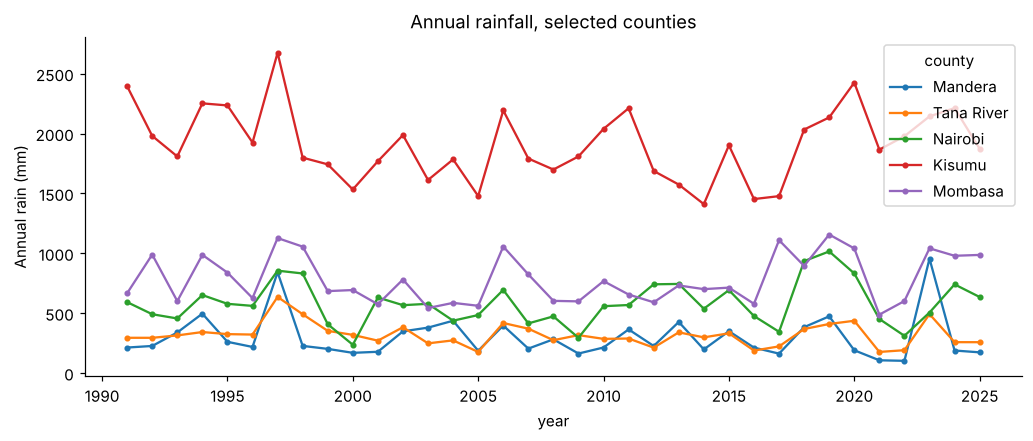

In [7]:
ext = csv("extremes.csv"); daily_ann = ext.pivot(index="year", columns="county", values="annual_rain_mm")
ax = daily_ann[["Mandera", "Tana River", "Nairobi", "Kisumu", "Mombasa"]].plot(figsize=(11, 4), marker=".")
ax.set_ylabel("Annual rain (mm)"); ax.set_title("Annual rainfall, selected counties")

## 3. Extremes
Longest dry spell (consecutive days < 1 mm), heavy-rain days (above the county's own 95th percentile of wet days), maximum 3-day rainfall, and hot days (apparent Tmax above the county's 95th percentile).

In [8]:
ext.groupby("county")[["longest_dry_spell_days", "heavy_rain_days", "max_3day_rain_mm", "hot_days"]].agg(["mean", "max"]).round(1)

longest_dry_spell_days      heavy_rain_days     max_3day_rain_mm        hot_days    
                             mean  max            mean max             mean    max     mean max
county                                                                                         
Busia                        10.9   21            14.3  29             83.9  131.2     17.8  39
Garissa                     108.2  175             2.1   6             40.2  114.0     16.9  57
Kilifi                       32.8   80             8.1  19             82.6  238.7     19.3  55
Kisumu                       13.3   47            13.1  35             83.7  131.2     17.7  44
Kwale                        34.7   80             9.6  20            106.3  344.6     18.3  51
Lamu                         48.9   82             6.7  20             64.8  321.8     18.7  53
Makueni                      63.1  134             5.8  16             60.9  125.8     18.9  45
Mandera                     123.9  201             2.4   9             66.6  241.8     18.2  49
Marsabit                    120.8  184             3.4  11             43.6   88.9     19.0  59
Mombasa                      30.0   80             9.3  19             85.1  288.1     18.3  57
Nairobi                      40.6  129             5.4  14             48.5   82.2     18.4  34
Tana River                   65.8  139             3.5  12             36.7   82.5     17.4  50
Turkana                      75.3  148             2.6  13             49.8   94.5     19.8  69
Wajir                       117.2  183             2.7  10             48.4  107.7     18.7  60

In [9]:
et = csv("extremes_trends.csv")
et.pivot(index="county", columns="variable", values="sen_slope_per_decade").round(2).join(
    et.pivot(index="county", columns="variable", values="significant_5pct").add_suffix(" sig"))

variable,heavy_rain_days,hot_days,longest_dry_spell_days,max_3day_rain_mm,heavy_rain_days sig,hot_days sig,longest_dry_spell_days sig,max_3day_rain_mm sig
county,,,,,,,,
Busia,1.33,1.43,1.30,3.11,False,False,True,False
Garissa,-0.00,2.67,0.00,-0.64,False,False,False,False
Kilifi,0.77,5.20,-0.00,10.17,False,True,False,False
Kisumu,1.33,3.48,1.43,0.80,False,True,False,False
Kwale,0.77,4.62,-0.00,4.50,False,True,False,False
Lamu,-0.00,2.86,3.48,1.76,False,False,False,False
Makueni,-0.00,5.00,-3.33,-3.27,False,True,False,False
Mandera,-0.00,3.33,-1.11,0.15,False,True,False,False
Marsabit,-0.00,8.57,-0.00,2.00,False,True,False,False


## 4. Drought indicator: 3-month rainfall as % of normal
| Level | % of 1991-2020 normal | Why |
|---|---|---|
| Normal | >= 75% | 75% is the lower edge of 'near normal' used in seasonal rainfall performance reporting |
| Watch | 50-75% | clearly below normal; comparable to NDMA 'Alert' |
| Warning | 25-50% | half or less of normal; comparable to NDMA 'Alarm' |
| Emergency | < 25% | near-total season failure |

When the 3-month normal is under **30 mm** (dry season) the % is not assessed: 5 mm vs a 10 mm normal is '50%' but means nothing. The class frequencies below check that Watch+ is uncommon but not rare.

In [10]:
csv("drought_class_frequency.csv", index_col=0)

,Normal,Watch,Warning,Emergency,Dry season (not assessed)
county,,,,,
Busia,89.7,9.8,0.6,0.0,0.0
Garissa,39.4,15.1,7.5,4.5,33.5
Kilifi,69.6,26.3,4.2,0.0,0.0
Kisumu,80.2,17.3,2.5,0.0,0.0
Kwale,71.2,24.6,4.2,0.0,0.0
Lamu,64.2,31.8,3.9,0.0,0.0
Makueni,57.8,20.9,3.9,0.6,16.8
Mandera,37.7,16.5,9.5,3.1,33.2
Marsabit,43.0,20.7,9.8,1.4,25.1


Text(0.5, 1.0, '3-month rainfall as % of normal (gaps = dry season)')

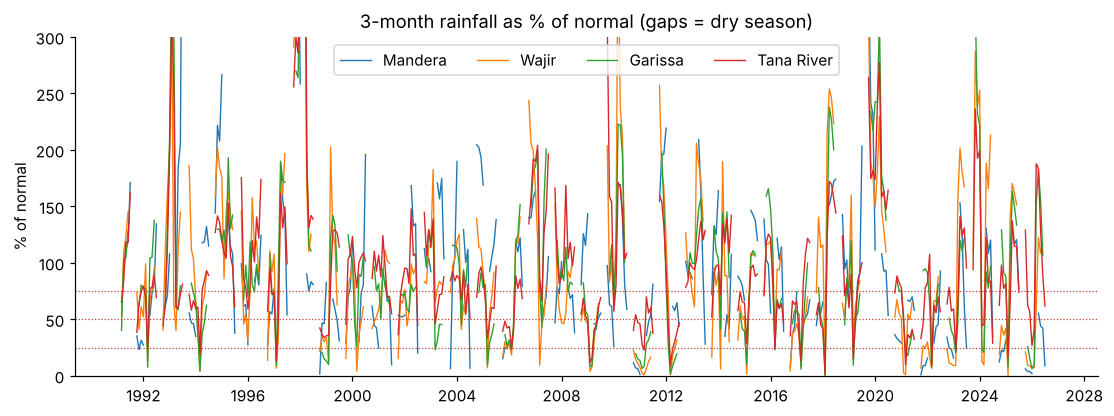

In [11]:
dro = pd.read_parquet(OUT / "drought.parquet")
fig, ax = plt.subplots(figsize=(12, 4))
for c in ["Mandera", "Wajir", "Garissa", "Tana River"]:
    g = dro[dro.county == c]; ax.plot(g.date, g.pct_of_normal, lw=0.9, label=c)
for y in (75, 50, 25): ax.axhline(y, color="#c0392b", ls=":", lw=0.8)
ax.set_ylim(0, 300); ax.set_ylabel("% of normal"); ax.legend(ncol=4); ax.set_title("3-month rainfall as % of normal (gaps = dry season)")

## 5. Heavy-rain indicator: 3-day total vs the county's own 99th percentile

In [12]:
csv("heavy_thresholds.csv", index_col=0).round(1)

,p95_3day_mm,p99_3day_mm,p99.9_3day_mm
county,,,
Busia,46.0,65.6,105.3
Garissa,10.7,26.9,42.2
Kilifi,23.1,50.3,147.0
Kisumu,45.4,66.7,98.5
Kwale,27.4,63.7,167.6
Lamu,19.5,39.8,92.3
Makueni,24.1,43.5,87.6
Mandera,15.3,32.8,107.2
Marsabit,15.2,31.6,58.6


## 6. Validation against history
### 6a. The 3 worst droughts and 3 worst heavy-rain periods our indicators flag (region-wide)

In [13]:
display(csv("worst_droughts.csv")); display(csv("worst_heavy_rain.csv"))

,rank,window_end,window,regional_mean_pct_of_normal,counties_warning_or_worse,driest_counties
0,1,2018-02,Dec 2017 - Feb 2018,18.4,5,"Garissa (0%), Tana River (1%), Marsabit (15%),..."
1,2,1997-02,Dec 1996 - Feb 1997,23.3,4,"Garissa (9%), Tana River (13%), Marsabit (14%)..."
2,3,2009-02,Dec 2008 - Feb 2009,27.6,4,"Garissa (8%), Tana River (12%), Marsabit (18%)..."


,rank,date,counties_over_p99,wettest_counties
0,1,2023-11-04,9,"Mandera (117 mm, 3.56x p99), Wajir (102 mm, 3...."
1,2,1992-05-24,3,"Kwale (345 mm, 5.41x p99), Mombasa (234 mm, 4...."
2,3,2017-05-10,3,"Mombasa (288 mm, 5.83x p99), Kwale (283 mm, 4...."


In [14]:
csv("per_county_worst.csv").pivot_table(index="county", columns="hazard", values="when", aggfunc=", ".join)

hazard,drought,heavy rain
county,,
Busia,"2026-09, 2006-01, 2015-01","1994-11-14, 2020-03-19, 1998-01-10"
Garissa,"2018-02, 2026-01, 2011-02","2023-11-21, 2019-11-26, 1993-01-08"
Kilifi,"2016-07, 2021-11, 2001-11","2025-10-30, 1992-05-24, 2019-05-24"
Kisumu,"2015-02, 2012-03, 1998-12","1995-04-13, 1997-11-22, 2009-05-12"
Kwale,"1991-11, 2016-12, 2001-11","1992-05-24, 2017-05-10, 2019-05-24"
Lamu,"1999-01, 2021-11, 2005-12","2020-05-11, 1995-05-27, 2018-10-26"
Makueni,"1997-02, 2022-03, 2012-03","2018-11-21, 2018-03-03, 2013-04-08"
Mandera,"2021-10, 2011-01, 1998-10","2023-11-19, 1997-10-28, 1993-05-03"
Marsabit,"2025-02, 1997-02, 2018-02","2016-04-29, 2024-05-05, 2023-11-03"


### 6b. Check against documented real events (ReliefWeb / IFRC / NDMA)
Matched = indicator reached **Warning** or worse in the listed county within the reported window +/- 1 month.

In [15]:
val = csv("validation.csv")
display(val[["event", "county", "window", "result", "indicator_detail"]])
s = val.groupby("event")["result"].value_counts().unstack(fill_value=0); display(s)
for ev, g in val.groupby("event"):
    m = (g.result == "matched").sum(); p = g.result.str.startswith("partial").sum()
    print(f"{ev}: matched {m}/{len(g)} counties, partial {p}; missed: {', '.join(g[g.result=='missed'].county) or 'none'}")
print("\nSources:")
for u in val.url.unique():
    print("-", u)

,event,county,window,result,indicator_detail
0,DR-2021,Mandera,2021-03-01 to 2022-12-31,matched,lowest 1% of normal
1,DR-2021,Wajir,2021-03-01 to 2022-12-31,matched,lowest 9% of normal
2,DR-2021,Garissa,2021-03-01 to 2022-12-31,matched,lowest 18% of normal
3,DR-2021,Marsabit,2021-03-01 to 2022-12-31,matched,lowest 22% of normal
4,DR-2021,Turkana,2021-03-01 to 2022-12-31,matched,lowest 2% of normal
5,DR-2021,Tana River,2021-03-01 to 2022-12-31,matched,lowest 34% of normal
6,FL-2023,Mandera,2023-10-15 to 2023-12-31,matched,max 3-day = 7.37x own p99
7,FL-2023,Wajir,2023-10-15 to 2023-12-31,matched,max 3-day = 3.39x own p99
8,FL-2023,Garissa,2023-10-15 to 2023-12-31,matched,max 3-day = 4.24x own p99
9,FL-2023,Tana River,2023-10-15 to 2023-12-31,matched,max 3-day = 2.48x own p99


result,matched,"missed (heavy rain, but prior 12 months not dry enough)",partial (Watch only),partial (minor season only)
event,,,,
DR-2021,6,0,0,0
DR-2025,5,0,1,1
FL-2023,5,0,0,0
FL-2024,4,0,1,0
WH-2019,1,9,1,0
WH-2023A,2,0,2,0
WH-2023B,2,3,0,0


DR-2021: matched 6/6 counties, partial 0; missed: none
DR-2025: matched 5/7 counties, partial 2; missed: none
FL-2023: matched 5/5 counties, partial 0; missed: none
FL-2024: matched 4/5 counties, partial 1; missed: none
WH-2019: matched 1/11 counties, partial 1; missed: none
WH-2023A: matched 2/4 counties, partial 2; missed: none
WH-2023B: matched 2/5 counties, partial 0; missed: none

Sources:
- https://reliefweb.int/report/kenya/kenya-drought-hunger-crisis-2021-emergency-appeal-mdrke049
- https://reliefweb.int/report/kenya/kenya-africa-floods-2023-operation-update-mdrke058
- https://reliefweb.int/disaster/FL-2024-000045-KEN
- https://go-api.ifrc.org/api/DownloadFile/93652/MDRKE068%20OU2
- https://reliefweb.int/report/kenya/kenya-flash-update-no-2-floods-5-november-2019
- https://www.the-star.co.ke/news/2023-04-23-rains-a-curse-for-drought-stricken-families


**Reading the misses:** a point estimate at the county HQ cannot see rain that fell upstream (e.g. Tana River floods are often driven by rain in the central highlands, far from Hola), and ERA5 smooths intense local storms (urban flash floods in Nairobi). These are recorded in LIMITATIONS.md.

### 6c. Rain after drought (compound drought-to-flood alert)
**Rule** (fixed before validation): 3-day rain at the county's own p95 / p99 / p99.9 (Watch / Warning / Emergency) when the previous 12 full months had at most 75% of their 1991-2020 normal. The 3-month drought indicator turns 'Normal' as soon as it rains and the heavy-rain indicator ignores what came before, so neither flags this on its own.

In [16]:
ws = json.loads((OUT / "whiplash_stats.json").read_text())
print(f"Episodes since 1991: {ws['episodes']} ({ws['episodes_warning_plus']} at Warning+); "
      f"{ws['episodes_per_county_decade']} per county per decade ({ws['warning_plus_per_county_decade']} at Warning+)")
print(f"1-in-100-day (p99) rain days: {ws['p99_rain_days']}, of which {ws['p99_rain_days_on_drought_land_pct']:.0f}% fell on drought-hit land")
print("Blind spot - when a rain-after-drought episode started, the 3-month drought indicator said:")
print(f"  Normal (or not assessed, dry season): {ws['blind_spot_drought_indicator_normal_pct']:.0f}% of episodes")
print(f"  below Warning (Normal, not assessed or Watch): {ws['blind_spot_drought_indicator_below_warning_pct']:.0f}% of episodes")

Episodes since 1991: 282 (104 at Warning+); 5.6 per county per decade (2.1 at Warning+)
1-in-100-day (p99) rain days: 1882, of which 17% fell on drought-hit land
Blind spot - when a rain-after-drought episode started, the 3-month drought indicator said:
  Normal (or not assessed, dry season): 65% of episodes
  below Warning (Normal, not assessed or Watch): 89% of episodes


In [17]:
wv = csv("whiplash_validation.csv")
wv["outcome"] = wv.result.str.split(" ").str[0]
display(wv[["event", "county", "window", "result", "indicator_detail"]])
counts = wv.groupby("event")["outcome"].value_counts().unstack(fill_value=0).reindex(columns=["matched", "partial", "missed"], fill_value=0)
counts.loc["TOTAL"] = counts.sum(); display(counts)
print("Sources:")
for src, u in wv[["source", "url"]].drop_duplicates().itertuples(index=False):
    print("-", src, u)

,event,county,window,result,indicator_detail
0,WH-2019,Mandera,2019-10-01 to 2019-11-30,"missed (heavy rain, but prior 12 months not dr...",prior 12 months 93% of normal; max 3-day = 3.6...
1,WH-2019,Wajir,2019-10-01 to 2019-11-30,"missed (heavy rain, but prior 12 months not dr...",prior 12 months 78% of normal; max 3-day = 1.5...
2,WH-2019,Marsabit,2019-10-01 to 2019-11-30,"missed (heavy rain, but prior 12 months not dr...",prior 12 months 80% of normal; max 3-day = 1.8...
3,WH-2019,Turkana,2019-10-01 to 2019-11-30,matched,prior 12 months 63% of normal; max 3-day = 1.8...
4,WH-2019,Garissa,2019-10-01 to 2019-11-30,partial (Watch only),prior 12 months 69% of normal; max 3-day = 3.7...
5,WH-2019,Lamu,2019-10-01 to 2019-11-30,"missed (heavy rain, but prior 12 months not dr...",prior 12 months 100% of normal; max 3-day = 1....
6,WH-2019,Kwale,2019-10-01 to 2019-11-30,"missed (heavy rain, but prior 12 months not dr...",prior 12 months 126% of normal; max 3-day = 1....
7,WH-2019,Mombasa,2019-10-01 to 2019-11-30,"missed (heavy rain, but prior 12 months not dr...",prior 12 months 116% of normal; max 3-day = 0....
8,WH-2019,Tana River,2019-10-01 to 2019-11-30,"missed (heavy rain, but prior 12 months not dr...",prior 12 months 79% of normal; max 3-day = 1.6...
9,WH-2019,Kisumu,2019-10-01 to 2019-11-30,"missed (heavy rain, but prior 12 months not dr...",prior 12 months 95% of normal; max 3-day = 1.1...


outcome,matched,partial,missed
event,,,
WH-2019,1,1,9
WH-2023A,2,2,0
WH-2023B,2,0,3
TOTAL,5,3,12


Sources:
- OCHA Kenya Flash Update No. 2: Floods (5 Nov 2019) https://reliefweb.int/report/kenya/kenya-flash-update-no-2-floods-5-november-2019
- The Star / NDMA, 'Rains a curse for drought-stricken families' (23 Apr 2023) https://www.the-star.co.ke/news/2023-04-23-rains-a-curse-for-drought-stricken-families
- IFRC Operation Update MDRKE058; UNICEF Kenya sitrep 15 Dec 2023 https://reliefweb.int/report/kenya/kenya-africa-floods-2023-operation-update-mdrke058


In [18]:
sens = csv("whiplash_sensitivity.csv")
(sens.style.apply(lambda r: ["background-color: #ffe08a; font-weight: bold" if r.published_rule else "" for _ in r], axis=1)
     .format({"episodes_per_county_decade": "{:.1f}"}).hide(axis="index"))

antecedent_months,dry_pct,matched,partial,county_events,episodes_per_county_decade,published_rule
6,60,3,2,20,4.6,False
6,75,4,2,20,8.4,False
6,90,6,6,20,13.3,False
12,60,2,2,20,2.5,False
12,75,5,3,20,5.6,True
12,90,7,5,20,11.4,False


1862 p99 rain days plotted (20 skipped: no 12-month history yet)


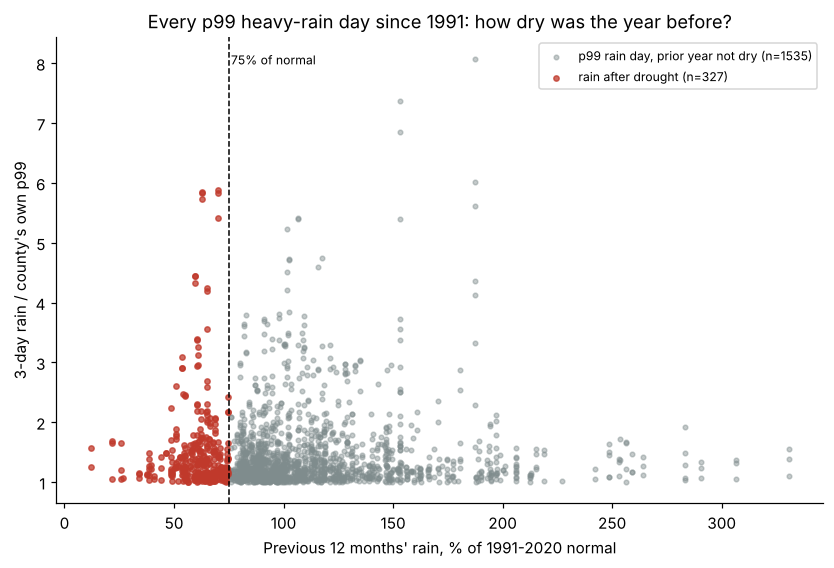

In [19]:
from sentinel import indicators as ind
mon = pd.read_parquet(OUT / "monthly.parquet"); hr = pd.read_parquet(OUT / "heavy_rain.parquet")
wh = ind.whiplash_indicator(hr, ind.antecedent_dryness(mon))   # same functions run_all.py uses
p99 = wh[wh.level.isin(["Warning", "Emergency"]) & wh.ante_pct.notna()]
is_wh = p99.whiplash_level != "Normal"
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(p99.ante_pct[~is_wh], p99.ratio_to_p99[~is_wh], s=9, alpha=0.45, color="#7f8c8d", label=f"p99 rain day, prior year not dry (n={(~is_wh).sum()})")
ax.scatter(p99.ante_pct[is_wh], p99.ratio_to_p99[is_wh], s=12, alpha=0.75, color="#c0392b", label=f"rain after drought (n={is_wh.sum()})")
ax.axvline(C.WHIPLASH_DRY_PCT, color="k", ls="--", lw=1); ax.text(C.WHIPLASH_DRY_PCT + 1, ax.get_ylim()[1] * 0.97, f"{C.WHIPLASH_DRY_PCT:.0f}% of normal", va="top", fontsize=8)
ax.set_xlabel("Previous 12 months' rain, % of 1991-2020 normal"); ax.set_ylabel("3-day rain / county's own p99")
ax.set_title("Every p99 heavy-rain day since 1991: how dry was the year before?"); ax.legend(loc="upper right", fontsize=8)
print(f"{len(p99)} p99 rain days plotted ({int(wh.level.isin(['Warning', 'Emergency']).sum() - len(p99))} skipped: no 12-month history yet)")

In [20]:
tot = counts.loc["TOTAL"]; pub = sens[sens.published_rule].iloc[0]
print("What the outputs show:")
print(f"- {ws['p99_rain_days_on_drought_land_pct']:.0f}% of 1-in-100-day rain days fell on land that had at most {C.WHIPLASH_DRY_PCT:.0f}% of normal rain over the previous year (red points, left of the dashed line).")
print(f"- When these episodes began, the standard 3-month drought indicator already read Normal or not assessed in {ws['blind_spot_drought_indicator_normal_pct']:.0f}% of cases, so a drought-only view would not have flagged them.")
miss = wv[wv.outcome == "missed"]; wet_year = miss.result.str.contains("not dry enough").sum()
print(f"- Against {int(tot.sum())} documented county-events the rule matched {tot['matched']}, reached Watch only in {tot['partial']} and missed {tot['missed']}; "
      f"{wet_year} of the {len(miss)} misses had heavy rain but a previous year wetter than {C.WHIPLASH_DRY_PCT:.0f}% of normal.")
print(f"- In the sensitivity grid the published rule ({pub.antecedent_months} months, {pub.dry_pct:.0f}%) gives {pub.matched} matches at {pub.episodes_per_county_decade:.1f} alerts per county per decade; "
      f"the most matches ({sens.matched.max()}) come with {sens.loc[sens.matched.idxmax(), 'episodes_per_county_decade']:.1f} alerts per county per decade.")

What the outputs show:
- 17% of 1-in-100-day rain days fell on land that had at most 75% of normal rain over the previous year (red points, left of the dashed line).
- When these episodes began, the standard 3-month drought indicator already read Normal or not assessed in 65% of cases, so a drought-only view would not have flagged them.
- Against 20 documented county-events the rule matched 5, reached Watch only in 3 and missed 12; 12 of the 12 misses had heavy rain but a previous year wetter than 75% of normal.
- In the sensitivity grid the published rule (12 months, 75%) gives 5 matches at 5.6 alerts per county per decade; the most matches (7) come with 11.4 alerts per county per decade.


## 7. Cyclone exposure (IBTrACS, 300 km from the county boundary)
Distances are computed in a Kenya-centred azimuthal equidistant projection (metres), not in degrees.

In [21]:
rk = csv("cyclone_ranking.csv"); display(rk)
dec = csv("cyclone_per_decade.csv")
dec[dec.county.isin([c.name for c in C.COUNTIES if c.coastal])].pivot(index="decade_label", columns="county", values="storms")

,county,tropical_storms_300km,storms_per_decade,any_system_300km,any_system_600km_context,closest_approach_km,seasons_covered,exposure_rank,storms_listed,exposure_class
0,Kilifi,1,0.22,1,8,209.0,1981-2026,1,IALY (2024),Low
1,Kwale,1,0.22,1,8,251.0,1981-2026,2,IALY (2024),Low
2,Mombasa,1,0.22,1,8,238.0,1981-2026,3,IALY (2024),Low
3,Tana River,1,0.22,1,7,144.0,1981-2026,4,IALY (2024),Low
4,Lamu,1,0.22,1,5,73.0,1981-2026,5,IALY (2024),Low
5,Garissa,1,0.22,1,4,77.0,1981-2026,6,IALY (2024),Low
6,Makueni,0,0.00,0,4,NaN,1981-2026,7,none,None recorded
7,Mandera,0,0.00,0,3,NaN,1981-2026,8,none,None recorded
8,Wajir,0,0.00,0,2,NaN,1981-2026,9,none,None recorded
9,Marsabit,0,0.00,0,1,NaN,1981-2026,10,none,None recorded


county,Kilifi,Kwale,Lamu,Mombasa
decade_label,,,,
1981-1990,0,0,0,0
1991-2000,0,0,0,0
2001-2010,0,0,0,0
2011-2020,0,0,0,0
2021-2026,1,1,1,1


Text(0.5, 1.0, 'Storm tracks within 600 km (blue) and 300 km exposure class')

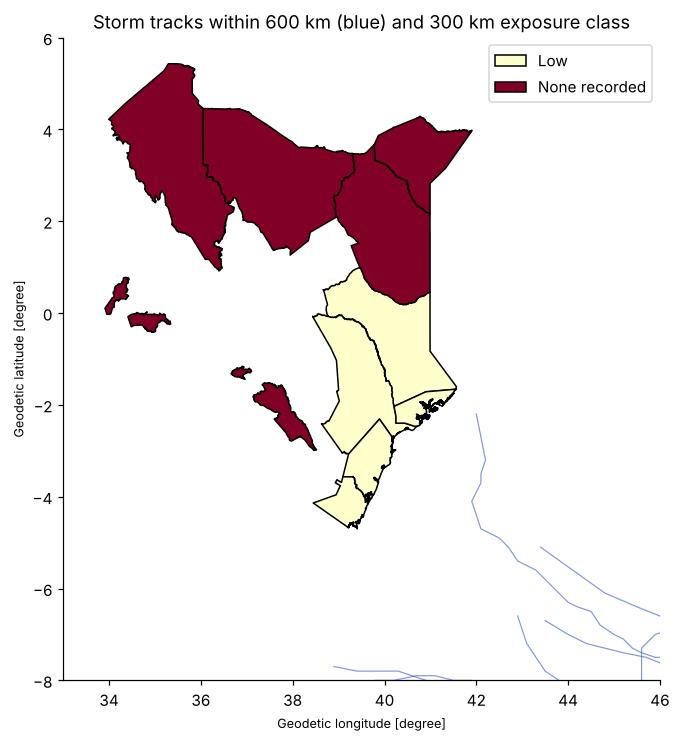

In [22]:
import geopandas as gpd
g = gpd.read_file(OUT / "counties_status.geojson")
tracks = pd.read_parquet(OUT / "cyclone_tracks.parquet")
ax = g.plot(column="cyclone_exposure_class", legend=True, figsize=(7, 8), edgecolor="k", cmap="YlOrRd")
for sid, t in tracks.sort_values("ISO_TIME").groupby("SID"):
    ax.plot(t.LON, t.LAT, lw=0.8, color="#3355cc", alpha=0.6)
ax.set_xlim(33, 46); ax.set_ylim(-8, 6); ax.set_title("Storm tracks within 600 km (blue) and 300 km exposure class")

Cyclones rarely reach Kenya: South-West Indian Ocean storms mostly track south of ~10 S. Low counts are the honest result, which is why the playbook ties cyclone actions to official KMD / RSMC La Reunion warnings rather than to our exposure count.

## 8. Population exposure (KNBS 2019 census)
People counts used for exposure and ranking are the **KNBS 2019 census** county totals (`population`). The WorldPop 2020 1 km raster summed inside each county boundary (`worldpop_2020`) is kept only as a cross-check; `worldpop_vs_census_pct` is how far it is from the census.

In [23]:
pop = csv("population.csv")
display(pop[["county", "population", "population_source", "census_2019", "worldpop_2020", "worldpop_vs_census_pct"]]
        .sort_values("worldpop_vs_census_pct").round(1))
print("Median |WorldPop - census| difference:", round(pop.worldpop_vs_census_pct.abs().median(), 1), "%")
print("Exposure uses census totals for all counties:", bool((pop.population == pop.census_2019).all()))
for f in sorted(OUT.glob("people_by_*.csv")):
    print("\n" + f.stem); display(pd.read_csv(f))

,county,population,population_source,census_2019,worldpop_2020,worldpop_vs_census_pct
10,Lamu,143920,KNBS 2019 census,143920,89892.0,-37.5
1,Marsabit,459785,KNBS 2019 census,459785,355053.2,-22.8
12,Mombasa,1208333,KNBS 2019 census,1208333,1040262.8,-13.9
13,Kwale,866820,KNBS 2019 census,866820,788721.7,-9.0
11,Kilifi,1453787,KNBS 2019 census,1453787,1399141.1,-3.8
5,Tana River,315943,KNBS 2019 census,315943,315753.8,-0.1
8,Kisumu,1155574,KNBS 2019 census,1155574,1206586.4,4.4
7,Nairobi,4397073,KNBS 2019 census,4397073,4633705.7,5.4
9,Busia,893681,KNBS 2019 census,893681,941985.9,5.4
6,Makueni,987653,KNBS 2019 census,987653,1074120.3,8.8


Median |WorldPop - census| difference: 11.4 %
Exposure uses census totals for all counties: True

people_by_cyclone_exposure_class


,level,counties,n_counties,people
0,Low,"Garissa, Kilifi, Kwale, Lamu, Mombasa, Tana River",6,4830156
1,None recorded,"Busia, Kisumu, Makueni, Mandera, Marsabit, Nai...",8,10469462



people_by_drought_level


,level,counties,n_counties,people
0,Dry season (not assessed),Garissa,1,841353
1,Normal,"Kilifi, Kisumu, Kwale, Lamu, Makueni, Mandera,...",10,8240535
2,Watch,"Busia, Nairobi, Turkana",3,6217730



people_by_forecast_heavy_level


,level,counties,n_counties,people
0,Normal,"Busia, Kilifi, Kisumu, Kwale, Lamu, Mombasa",6,5722115
1,Warning,"Tana River, Wajir",2,1097206
2,Watch,"Garissa, Makueni, Mandera, Marsabit, Nairobi, ...",6,8480297



people_by_observed_heavy_level


,level,counties,n_counties,people
0,Normal,"Busia, Garissa, Kilifi, Kwale, Lamu, Mandera, ...",10,12380663
1,Watch,"Kisumu, Makueni, Marsabit, Tana River",4,2918955
